In [ ]:
# analysis PLOT for the line plots

import pandas as pd
import os
import sys
import numpy as np
import matplotlib.pyplot as plt


def read_AHA_csv(merged_df, device, lengths, collision_fields=['Combined_Collision'], diameters=None, conestr=''): 
    main_path = '/data_fast/Work/MS_HF_cohort/images'
    #, RV_Collision, TV_Collision, 'PM_Collision', 'Combined_Collision'
      
 
    for i, length in enumerate(lengths): #, 15, 20, 25, 30, 35, 40, 45]:  #[22, 27, 32, 37, 42]: 
        for collision_field in collision_fields: #['RV_Collision', 'TV_Collision', 'PM_Collision', 'Combined_Collision']: 
            diameter = diameters[i] if diameters is not None else None
            #, RV_Collision, TV_Collision, 'PM_Collision', 'Combined_Collision'
            if collision_field=='Combined_Collision':
                images_outpath=f'{main_path}/{device}{conestr}/'
                add_legend=True
            else: 
                images_outpath=f'{main_path}/{device}{conestr}/{collision_field}/'
                add_legend=False


            csv_outfile=f'{images_outpath}/sum_plots/RV_septum_polar_sum_{device}_L{length}.csv'
            
            #print(f'CSV outfile: {csv_outfile}')
            df= pd.read_csv(csv_outfile)
            #display(df)
            if diameter is not None: 
                label= f'{device}_L{length}_D{diameter:1.1f}_{collision_field}'
            else:     
                label= f'{device}_L{length}_{collision_field}'
                # Create formatted column
            df[label] = df.apply(lambda row: f"{row['mean']:.1f} ± {row['std']:.1f}", axis=1)
            # Subset to AHA_region and formatted column
            df = df[["AHA_region", label]]

            # Merge
            if merged_df is None:
                merged_df = df
            else:
                merged_df = pd.merge(merged_df, df, on="AHA_region", how="outer")
    return merged_df


def extract_mean_std_from_formatted(formatted_str):
    """Extract mean and std from formatted string 'mean ± std'"""
    try:
        parts = formatted_str.split(' ± ')
        mean = float(parts[0])
        std = float(parts[1])
        return mean, std
    except:
        return np.nan, np.nan
    
        under_color = "#4da6ff"
        under_color = "#66b38c"        
        under_color = "#ff9933"


def get_specs(): 
    device_colors = {
        'Micra': '#003d7a', ## '#2596be',
        'MicraTPS': '#003d7a',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#cc6600',  # '#b2182b',
        'AveirAR': '#00664f'  #  '#92c5de'
    }
    device_linestyles = {
        'Micra': '-',
        'MicraTPS': '-',
        'OtherPallete': '--',
        'AveirVR': '-.',
        'AveirAR': '-', 
        '20': '-', 
        '21': '--', 
        '22': ':', 
        '23': '.-'
    }
    device_markers = {
        'Micra': 'o',
        'MicraTPS': 'o',
        'OtherPallete': 's',
        'AveirVR': '^',
        'AveirAR': 'D', 
        20: 'o', 
        21: 's', 
        22: '^', 
        23: 'D'
    }
    init_lens = {
        'AveirVR': 38,
        'AveirAR': 32.2,
        'MicraTPS': 25.9  # If you use MicraTPS as a device name
    }
    init_diams = {
        'AveirVR': 6.5,
        'AveirAR': 6.5,
        'MicraTPS': 6.7  # If you use MicraTPS as a device name
    }
    return device_colors, device_linestyles, device_markers, init_lens, init_diams

def create_summary_table(merged_df, output_path=None):
    """Create summary statistics table"""
    # Extract numeric data from formatted strings
    numeric_data = {}
    
    for col in merged_df.columns:
        if col != 'AHA region':
            means = []
            stds = []
            for val in merged_df[col]:
                if pd.notna(val):
                    mean, std = extract_mean_std_from_formatted(val)
                    means.append(mean)
                    stds.append(std)
            
            numeric_data[col] = {
                'mean_avg': np.nanmean(means),
                'mean_std': np.nanstd(means),
                'std_avg': np.nanmean(stds),
                'std_std': np.nanstd(stds)
            }
    
    summary_df = pd.DataFrame(numeric_data).T
    
    if output_path:
        summary_df.to_csv(f'{output_path}/summary_statistics.csv')
    
    return summary_df
    
def plot_collision_data_regions_as_lines(merged_df, output_path=None, plot_CS=True, collision_fields = ['PM_Collision', 'TV_Collision', 'RV_Collision', 'Combined_Collision'], add_init_val=True):
    """
    Plot mean and standard deviation over lengths with each AHA region as a separate line
    for each device and collision field combination
    
    Parameters:
    merged_df: DataFrame with formatted collision data
    output_path: Optional path to save plots
    plot_CS: Boolean to determine if plotting CS regions (>=20) or AHA regions (<20)
    """
    if plot_CS:
        # Keep rows where 'AHA region' >= 20
        merged_df = merged_df[merged_df['AHA region'] >= 20]
    else:
        # Keep rows where 'AHA region' < 20
        merged_df = merged_df[merged_df['AHA region'] < 20]

    # Extract device names, lengths, and collision fields from column names
    columns = [col for col in merged_df.columns if col != 'AHA region']

    # Parse column names to extract components
    data_info = []
    for col in columns:
        parts = col.split('_')
        if len(parts) >= 3:
            device = parts[0]
            length_part = parts[1].replace('L', '')
            
            # Check if there's a diameter component (D followed by number)
            diameter = None
            collision_start_idx = 2
            
            if len(parts) > 3 and parts[2].startswith('D'):
                try:
                    diameter = float(parts[2].replace('D', ''))
                    collision_start_idx = 3
                except ValueError:
                    # If D part can't be converted to float, treat as part of collision_field
                    pass
            
            collision_field = '_'.join(parts[collision_start_idx:])
            
            # Handle device name mapping
            if device == 'Micra': 
                device = 'MicraTPS'
            
            data_info.append({
                'column': col,
                'device': device,
                'length': float(length_part),
                'diameter': diameter,
                'collision_field': collision_field
            })
    
    # Convert to DataFrame for easier manipulation
    info_df = pd.DataFrame(data_info)

    # Get unique values
    devices = sorted(info_df['device'].unique())
    
    aha_regions = sorted(merged_df['AHA region'].unique())
    
    # Get device specifications
    device_colors, device_linestyles, device_markers, init_lens, init_diams = get_specs()
    
    # Define region colors and styles
    if plot_CS:
        region_colors = {
            20: "#FF4DFF",  # Left Bundle - magentaplot_collision_data_regions_as_lines
            21: '#cc6600',  # Anterior Branch - orange
            22: "#003d7a",  # Posterior Branch - dark blue
            23: "#00664f"   # Septal Branch - dark green
        }
        region_names = {
            20: 'Left Bundle Branch',
            21: 'Left Anterior Fascicle', 
            22: 'Left Posterior Fascicle',
            23: 'Left Septal Fascicle'
        }
        
    else:
        # Generate colors for AHA regions
        import matplotlib.cm as cm
        cmap = cm.get_cmap('tab10')
        region_colors = {region: cmap(i/len(aha_regions)) for i, region in enumerate(aha_regions)}
        region_names = {region: f'AHA Region {region}' for region in aha_regions}
    
    # Create plots for each collision field and device combination
    for collision_field in collision_fields:
        # Get title string
        if collision_field.startswith('Combined_Collision'): 
            title_str = 'Combined collision risk'
        elif collision_field.startswith('RV_Collision'): 
            title_str = 'RV endocardium collision risk'
        elif collision_field.startswith('TV_Collision'): 
            title_str = 'Tricuspid valve structures collision risk'
        elif collision_field.startswith('PM_Collision'): 
            title_str = 'Papillary muscles and moderator band collision risk'
        else: 
            title_str = collision_field
            
        # Get devices that have data for this collision field
        
        if add_init_val is False: 
            available_devices=['MicraTPS'] # only plot MicraTPS without initial length/diameter]
        else: 
            available_devices = info_df[info_df['collision_field'] == collision_field]['device'].unique()
        n_devices = len(available_devices)
        
        if n_devices == 0:
            continue
            
        # Create subplots - one per device
        fig, axes = plt.subplots(1, n_devices, figsize=(5*n_devices, 5))
        
        # Handle single device case
        if n_devices == 1:
            axes = [axes]
        
        # Set main title
        region_type = "LBBAP region" if plot_CS else "AHA Region"
        if add_init_val: 
            fig.suptitle(f'{title_str} - Mean ± SD by Length and {region_type}', fontsize=16, y=0.98, fontweight='bold')

        for device_idx, device in enumerate(available_devices):
            ax = axes[device_idx]
            
            # Get columns for this device and collision field
            device_cols_info = info_df[
                (info_df['device'] == device) & 
                (info_df['collision_field'] == collision_field)
            ]
            
            if len(device_cols_info) == 0:
                continue
                
            # Determine if we're plotting by diameter or length
            has_diameter = device_cols_info['diameter'].notna().any()
            x_axis = 'diameter' if has_diameter else 'length'
            x_label = 'Diameter (mm)' if has_diameter else 'Length (mm)'
            
            # Plot each region as a separate line
            for aha_region in aha_regions:
                region_data = merged_df[merged_df['AHA region'] == aha_region]
                marker=device_markers.get(aha_region, 'o')
                
                if len(region_data) == 0:
                    continue
                
                # Extract data for this region
                x_values = []
                means = []
                stds = []
                
                for _, col_info in device_cols_info.iterrows():
                    col = col_info['column']
                    x_val = col_info[x_axis] if has_diameter else col_info['length']
                    
                    # Get formatted value
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            x_values.append(x_val)
                            means.append(mean)
                            stds.append(std)
                
                if x_values:  # Only plot if we have data
                    x_values = np.array(x_values)
                    means = np.array(means)
                    stds = np.array(stds)
                    
                    # Sort by x values
                    sort_idx = np.argsort(x_values)
                    x_values = x_values[sort_idx]
                    means = means[sort_idx]
                    stds = stds[sort_idx]
                    
                    # Plot line with error bars
                    region_color = region_colors.get(aha_region, 'black')
                    region_name = region_names.get(aha_region, f'Region {aha_region}')
                    if device=='AveirVR': 
                        ax.plot(x_values, means, label=region_name, linewidth=2, 
                           color=region_color, marker=marker, markersize=6)
                    else: 
                        ax.plot(x_values, means, linewidth=2, 
                           color=region_color, marker=marker, markersize=6)
                    ax.fill_between(x_values, means - stds, means + stds, 
                                   color=region_color, alpha=0.2)
            
            # Customize subplot
            if add_init_val: 
                ax.set_title(f'{device}', fontsize=14)
                ax.set_xlabel(x_label, fontsize=12)
                ax.set_ylabel('Collision (%)', fontsize=12)
                ax.set_yticks([0, 25, 50, 75, 100])
                ax.set_ylim(0, 100)
                ax.grid(True, alpha=0.3)
            else: 
                ax.set_yticks([0, 25, 50, 75, 100])
                ax.set_ylim(0, 100)
                ax.grid(True, alpha=0.3)
                ax.tick_params(axis='y', labelsize=20)
                ax.set_xticks([15, 25, 35, 45])

                ax.tick_params(axis='x', labelsize=20)
            plot_fig=False
            # Add legend
            if device=='AveirVR' and collision_field=='Combined_Collision' and plot_fig:
                #ax.legend(fontsize=12, loc="upper left")
                # ax.legend(
                #     fontsize=12,
                #     loc='upper left',
                #     bbox_to_anchor=(1.02, 1),   # push outside the axes
                #     borderaxespad=0
                # )
                # Get handles/labels only from the last subplot
                handles, labels = ax.get_legend_handles_labels()

                fig.legend(
                    handles, labels,
                    loc="lower center",   # across the full figure
                    ncol=4,               # arrange in columns
                    frameon=True,
                    bbox_to_anchor=(0.5, -0.1),
                    fontsize=12
                )
            # Add initial length/diameter annotation if applicable
            init_val = init_diams.get(device) if has_diameter else init_lens.get(device)
            if init_val is not None and add_init_val: 
                ax.axvline(x=init_val, color=device_colors.get(device, '#000000'), 
                          linestyle='--', alpha=0.7, linewidth=1)
                if collision_field=='Combined_Collision':
                    y_val=25
                else: 
                    y_val=95
                ax.text(init_val, y_val, f'Initial\n{x_axis}', ha='center', va='top',
                       color=device_colors.get(device, '#000000'), fontsize=12,
                       bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
        
        plt.tight_layout()
        
        # Save plot if output path provided
        if output_path:
            os.makedirs(output_path, exist_ok=True)
            region_suffix = "LBBAP_regions" if plot_CS else "AHA_regions"
            filename = f'{output_path}/{collision_field}_regions_as_lines_{region_suffix}.png'
            plt.savefig(filename, dpi=300, bbox_inches='tight')
            print(f'Saved: {filename}')
        
        plt.show()


# Helper function to extract mean and std from formatted string
def extract_mean_std_from_formatted(formatted_val):
    """
    Extract mean and standard deviation from a formatted string like "45.2 ± 12.3"
    """
    try:
        if isinstance(formatted_val, str) and '±' in formatted_val:
            parts = formatted_val.split('±')
            mean = float(parts[0].strip())
            std = float(parts[1].strip())
            return mean, std
        else:
            # If it's just a number, assume std = 0
            mean = float(formatted_val)
            return mean, 0.0
    except (ValueError, AttributeError, IndexError):
        return np.nan, np.nan



In [38]:
plt.ioff()  # Add this at the beginning of your script
def plot_collision_data_by_aha(merged_df, output_path=None, plot_CS=True,
                                collision_fields=['PM_Collision', 'TV_Collision', 'RV_Collision', 'Combined_Collision'], 
                                fig=None, axes=None, plot_fig=True, create_new_fig=True):
    """
    Plot mean and standard deviation over lengths for each AHA region and collision field
    
    Parameters:
    merged_df: DataFrame with formatted collision data
    output_path: Optional path to save plots
    create_new_fig: If True, creates new figure/axes. If False, uses existing fig/axes for overlay
    """
    if plot_CS:
        # Keep rows where 'AHA region' >= 20
        merged_df = merged_df[merged_df['AHA region'] >= 20]
    else:
        # Keep rows where 'AHA region' < 20
        merged_df = merged_df[merged_df['AHA region'] < 20]

    # Extract device names, lengths, and collision fields from column names
    columns = [col for col in merged_df.columns if col != 'AHA region']

    # Parse column names to extract components
    data_info = []
    for col in columns:
        parts = col.split('_')
        if len(parts) >= 3:
            device = parts[0]
            length_part = parts[1].replace('L', '')
            
            # Check if there's a diameter component (D followed by number)
            diameter = None
            collision_start_idx = 2
            
            if len(parts) > 3 and parts[2].startswith('D'):
                try:
                    diameter = float(parts[2].replace('D', ''))
                    collision_start_idx = 3
                except ValueError:
                    # If D part can't be converted to float, treat as part of collision_field
                    pass
            
            collision_field = '_'.join(parts[collision_start_idx:])
            
            # Handle device name mapping
            if device == 'Micra': 
                device = 'MicraTPS'
            
            data_info.append({
                'column': col,
                'device': device,
                'length': float(length_part),
                'diameter': diameter,
                'collision_field': collision_field
            })
    
    # Convert to DataFrame for easier manipulation
    info_df = pd.DataFrame(data_info)

    # Get unique values
    devices = sorted(info_df['device'].unique())
    aha_regions = sorted(merged_df['AHA region'].unique())
    

    # Create plots for each collision field
    for collision_field in collision_fields:
        # First pass: collect all data to determine global y-axis limits
        all_means = []
        all_stds = []
        n_regions = len(aha_regions)
        for aha_region in aha_regions:
            if plot_CS and aha_region < 20: 
                continue
            elif not plot_CS and aha_region >= 20: 
                continue
            
            region_data = merged_df[merged_df['AHA region'] == aha_region]
            
            for device in devices:
                device_cols = info_df[
                    (info_df['device'] == device) & 
                    (info_df['collision_field'] == collision_field)
                ]['column'].tolist()
                
                for col in device_cols:
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            all_means.append(mean)
                            all_stds.append(std)
        
        # Calculate global y-axis limits
        if all_means and all_stds:
            all_means = np.array(all_means)
            all_stds = np.array(all_stds)
            y_min = np.min(all_means - all_stds)
            y_max = np.max(all_means + all_stds)
            # Add some padding
            y_range = y_max - y_min
            y_min = max(0, y_min - 0.05 * y_range)
            y_max = y_max + 0.05 * y_range
        else:
            y_min, y_max = 0, 100
        
        n_regions = len(aha_regions)
        n_rows = 1
        n_cols = n_regions
        
        # Only create new figure if requested AND if fig/axes not provided
        if fig is None or create_new_fig:
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 5))
            # Mark as new figure
            fig._is_new = True
        else:
            # Reusing existing figure
            fig._is_new = False
        
        # Handle different subplot configurations
        if not isinstance(axes, (list, np.ndarray)):
            # Single axes object - wrap in list
            axes = [axes]
        elif isinstance(axes, np.ndarray):
            # NumPy array - flatten and convert to list
            axes = axes.flatten().tolist()
        
        offset = 10
        xoffset = 0
        if collision_field.startswith('Combined_Collision'): 
            title_str = 'Combined collision risk'
            offset = -20
            xoffset = 0
        elif collision_field.startswith('RV_Collision'): 
            title_str = 'RV endocardium collision risk'
            if not plot_CS: 
                offset = -15
            else: 
                xoffset = -5 
                print('Change xoffset for RV collision for plotCS')
        elif collision_field.startswith('TV_Collision'): 
            title_str = 'Tricuspid valve structures collision risk'
        elif collision_field.startswith('PM_Collision'): 
            title_str = 'Papillary muscles and moderator band collision risk'
        else: 
            title_str = collision_field
        print(f'Y OFFSET: {offset}')

        # Only set title if creating new figure
        if fig._is_new:
            if plot_CS: 
                fig.suptitle(f'{title_str} - Mean ± SD by Length and LBBAP region', 
                           fontsize=16, y=0.98, fontweight='bold')
            else: 
                fig.suptitle(f'{title_str} - Mean ± SD by Length and AHA Region', 
                           fontsize=18, y=0.98, fontweight='bold')
        
        print(axes[0])
        for i, aha_region in enumerate(aha_regions):
            if aha_region == 2 and collision_field.startswith('Combined_Collision'): 
                xoffset = 5

            ax = axes[i]
            
            # Get data for this AHA region
            region_data = merged_df[merged_df['AHA region'] == aha_region]
            
            for device in devices:
                device_cols = info_df[
                    (info_df['device'] == device) & 
                    (info_df['collision_field'] == collision_field)
                ]['column'].tolist()

                if not device_cols:
                    continue
                
                # Extract lengths and values
                lengths = []
                means = []
                stds = []
                diameters = []
                for col in device_cols:
                    length = info_df[info_df['column'] == col]['length'].iloc[0]
                    diameter = info_df[info_df['column'] == col]['diameter'].iloc[0]
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            lengths.append(length)
                            if diameter is not None: 
                                diameters.append(diameter)
                            means.append(mean)
                            stds.append(std)
                
                if lengths:
                    lengths = np.array(lengths)                    
                    means = np.array(means)
                    stds = np.array(stds)
                    if diameter is not None: 
                        diameters = np.array(diameters)
                    
                    # Sort by length
                    sort_idx = np.argsort(lengths)
                    lengths = lengths[sort_idx]
                    means = means[sort_idx]
                    stds = stds[sort_idx]
                    
                    device_colors, device_linestyles, device_markers, init_lens, init_diams = get_specs()
                        # Colors for devices]
                    if not create_new_fig and not plot_fig: 
                        device_colors = {'AveirVR': '#8B0000', 'AveirAR': '#013501', 'MicraTPS': '#00008B',  'Micra': "#002B00"}
                        device_linestyles={'AveirVR': ':', 'AveirAR': ':', 'MicraTPS': ":"}
                    if diameter is not None: 
                        ax.plot(diameters, means, label=device, linewidth=2, 
                                color=device_colors.get(device, '#000000'), 
                                linestyle=device_linestyles.get(device, '-'),
                                marker=device_markers.get(device, 'o'))
                        ax.fill_between(diameters, means - stds, means + stds, 
                                        color=device_colors.get(device, '#000000'), alpha=0.2) 
                        init_len = init_diams.get(device)
                        if init_len is not None and init_len in diameters:
                            idx = np.where(lengths == init_len)[0]
                            if len(idx) > 0:
                                y_val = means[idx[0]]
                                y_offset = offset
                                if device == 'AveirAR': 
                                    y_offset = offset * 1.5
                                ax.annotate(
                                    device,
                                    xy=(init_len, y_val),
                                    xytext=(init_len + xoffset, y_val + y_offset),
                                    arrowprops=dict(facecolor=device_colors.get(device, '#000000'), 
                                                  shrink=0.05, width=2),
                                    ha='center', color=device_colors.get(device, '#000000'), fontsize=12
                                )
                    else: 
                        ax.plot(lengths, means, label=device, linewidth=2, 
                                color=device_colors.get(device, '#000000'), 
                                linestyle=device_linestyles.get(device, '-'),
                                marker=device_markers.get(device, 'o'))
                        ax.fill_between(lengths, means - stds, means + stds, 
                                        color=device_colors.get(device, '#000000'), alpha=0.2) 
                        
                        init_len = init_lens.get(device)
                        if init_len is not None and init_len in lengths and plot_fig:
                            idx = np.where(lengths == init_len)[0]
                            if len(idx) > 0:
                                y_val = means[idx[0]]
                                y_offset = offset
                                if device == 'AveirAR': 
                                    if offset > 0: 
                                        y_offset = offset * 1.5                                
                                    elif collision_field == 'Combined_Collision': 
                                        if aha_region == 14 or aha_region == 3:
                                            y_offset = offset + 5
                                            xoffset = 0
                                    elif collision_field == 'RV_Collision': 
                                        if aha_region == 14: 
                                            y_offset = offset - 10
                                
                                ax.annotate(
                                    device,
                                    xy=(init_len, y_val),
                                    xytext=(init_len + xoffset, y_val + y_offset),
                                    arrowprops=dict(facecolor=device_colors.get(device, '#000000'), 
                                                  shrink=0.05, width=2),
                                    ha='center',
                                    color='#000000', fontsize=12
                                )
            
            # Only set titles/labels if creating new figure
            if fig._is_new:
                if plot_CS and aha_region == 20: 
                    ax.set_title('Left Bundle', color="#FF4DFF", fontsize=14)
                elif plot_CS and aha_region == 21: 
                    ax.set_title('Anterior Branch', color='#cc6600', fontsize=14)
                elif plot_CS and aha_region == 22: 
                    ax.set_title('Posterior Branch', color="#003d7a", fontsize=14)
                elif plot_CS and aha_region == 23: 
                    ax.set_title('Septal Branch', color="#00664f", fontsize=14)
                else: 
                    ax.set_title(f'AHA Region {aha_region}', fontsize=16)
                
                if diameter is not None: 
                    ax.set_xlabel('Diameters')
                else: 
                    ax.set_xlabel('Length (mm)', fontsize=14)
                ax.set_ylabel('Collision (%)', fontsize=14)
                ax.set_yticks([0, 25, 50, 75, 100])
                ax.grid(True, alpha=0.3)
                ax.set_ylim(0, 100)
            
            #Update legend every time to show all datasets
            if i == 0 and plot_fig: 
                handles, labels = ax.get_legend_handles_labels()
                # Remove duplicate labels
                by_label = dict(zip(labels, handles))
                ax.legend(by_label.values(), by_label.keys(), fontsize=14, loc="upper left")
        
        # Hide empty subplots (only if creating new figure)
        if fig._is_new:
            for i in range(n_regions, len(axes)):
                axes[i].set_visible(False)
        
        plt.tight_layout()
        
        # Save plot if output path provided
        if output_path:
            os.makedirs(output_path, exist_ok=True)
            if plot_CS: 
                plt.savefig(f'{output_path}/{collision_field}_by_LBBAP_region.png', 
                       dpi=300, bbox_inches='tight')
                print(f'{output_path}/{collision_field}_by_LBBAP_region.png')
            else: 
                plt.savefig(f'{output_path}/{collision_field}_by_AHA_region.png', 
                        dpi=300, bbox_inches='tight')
                print(f'{output_path}/{collision_field}_by_AHA_region.png')
    
    # Only show plot at the very end if plot_fig is True
    # if plot_fig: 
    #     plt.show()
    
    return fig, axes
def calculate_collision_diff(merged_df, merged_df_cone,aha_regions = [2,3,8,9,14]):
    """
    Calculate the difference between cone and standard collision data.
    Returns difference dataframe and summary statistics.
    """
    # Create difference dataframe
    merged_df_diff = merged_df.copy()
    
    # Get all collision columns (exclude 'AHA region')
    collision_cols = [col for col in merged_df.columns if col != 'AHA region']
    
    # Calculate differences for each collision column
    for col in collision_cols:
        # Extract mean values from formatted strings
        merged_df_means = []
        merged_df_cone_means = []
        
        for i, row in merged_df.iterrows():
            if pd.notna(row[col]):
                mean, _ = extract_mean_std_from_formatted(row[col])
                merged_df_means.append(mean)
            else:
                merged_df_means.append(np.nan)
        
        for i, row in merged_df_cone.iterrows():
            cone_col = col.replace('_Collision', '_Collision_Cone')
            if cone_col in merged_df_cone.columns and pd.notna(row[cone_col]):
                mean, _ = extract_mean_std_from_formatted(row[cone_col])
                merged_df_cone_means.append(mean)
            else:
                merged_df_cone_means.append(np.nan)
        
        # Calculate difference
        diff_values = np.array(merged_df_cone_means) - np.array(merged_df_means)
        merged_df_diff[col] = diff_values
    
    # Parse column names for summary statistics
    data_info = []
    for col in collision_cols:
        parts = col.split('_')
        if len(parts) >= 3:
            device = parts[0]
            length_part = parts[1].replace('L', '')
            collision_field = '_'.join(parts[2:])
            
            if device == 'Micra':
                device = 'MicraTPS'
            
            data_info.append({
                'column': col,
                'device': device,
                'length': float(length_part),
                'collision_field': collision_field
            })
    
    info_df = pd.DataFrame(data_info)
    
    # Calculate summary statistics
    devices = sorted(info_df['device'].unique())
     # sorted(merged_df['AHA region'].unique())
    
    summary_stats = []
    
    for device in devices:
        device_cols = info_df[info_df['device'] == device]['column'].tolist()
        
        for aha_region in aha_regions:
            region_idx = merged_df[merged_df['AHA region'] == aha_region].index
            
            if len(region_idx) == 0:
                continue
            
            # Get differences for this device/region across all lengths
            diffs_for_region = []
            lengths_list = []
            
            for col in device_cols:
                length = info_df[info_df['column'] == col]['length'].iloc[0]
                lengths_list.append(length)
                
                diff_val = merged_df_diff.loc[region_idx[0], col]
                if not np.isnan(diff_val):
                    diffs_for_region.append(diff_val)
            
            if diffs_for_region:
                avg_diff = np.mean(diffs_for_region)
                std_diff = np.std(diffs_for_region)
                min_diff = np.min(diffs_for_region)
                max_diff = np.max(diffs_for_region)
                
                summary_stats.append({
                    'Device': device,
                    'AHA Region': aha_region,
                    'Avg Difference': avg_diff,
                    'Std Difference': std_diff,
                    'Min Difference': min_diff,
                    'Max Difference': max_diff,
                    'Lengths Tested': sorted(lengths_list)
                })
    
    summary_df = pd.DataFrame(summary_stats)
    
    return merged_df_diff, summary_df

def display_collision_diff_summary(summary_df):
    # Display summary by device and AHA region
    print("=" * 100)
    print("COLLISION DIFFERENCE SUMMARY (Cone - Standard)")
    print("=" * 100)
    print(summary_df.to_string(index=False))

    # Group by device for easier viewing
    print("\n" + "=" * 100)
    print("SUMMARY BY DEVICE")
    print("=" * 100)
    for device in summary_df['Device'].unique():
        device_data = summary_df[summary_df['Device'] == device]
        print(f"\n{device}:")
        print(f"  Average difference across all regions: {device_data['Avg Difference'].mean():.2f}%")
        print(f"  Range: {device_data['Avg Difference'].min():.2f}% to {device_data['Avg Difference'].max():.2f}%")

    # Group by AHA region
    print("\n" + "=" * 100)
    print("SUMMARY BY AHA REGION")
    print("=" * 100)
    for region in [2,3,8,9,14]:  #sorted(summary_df['AHA Region'].unique()):
        region_data = summary_df[summary_df['AHA Region'] == region]
        print(f"\nAHA Region {region}:")
        for _, row in region_data.iterrows():
            print(f"  {row['Device']:12s}: {row['Avg Difference']:6.2f}% ± {row['Std Difference']:.2f}% " +
                f"(range: {row['Min Difference']:.2f}% to {row['Max Difference']:.2f}%)")
def format_journal_table(summary_df):
    # Create publication-ready summary table
    summary_table = summary_df[['Device', 'AHA Region', 'Avg Difference', 'Std Difference']].copy()
    summary_table.columns = ['Device', 'AHA Region', 'Mean Difference (%)', 'SD (%)']
    summary_table = summary_table.sort_values(['Device', 'AHA Region'])

    # Round to 1 decimal place
    summary_table['Mean Difference (%)'] = summary_table['Mean Difference (%)'].round(1)
    summary_table['SD (%)'] = summary_table['SD (%)'].round(1)

    # Format as "value ± SD"
    summary_table['Difference'] = summary_table.apply(
        lambda x: f"{x['Mean Difference (%)']:5.1f} ± {x['SD (%)']:4.1f}", axis=1
    )

    # Create pivot table for cleaner presentation
    pivot_table = summary_table.pivot_table(
        index='Device',
        columns='AHA Region',
        values='Difference',
        aggfunc='first'
    )

    # Add "All Regions" column as the average across all 5 RV septal regions
    all_regions_data = []
    for device in pivot_table.index:
        device_data = summary_df[summary_df['Device'] == device]
        avg_mean = device_data['Avg Difference'].mean()
        avg_std = device_data['Std Difference'].mean()
        formatted_all = f"{avg_mean:5.1f} ± {avg_std:4.1f}"
        all_regions_data.append(formatted_all)

    pivot_table['All Regions'] = all_regions_data
    # Format table with better spacing for Word
    pivot_table_str = pivot_table.to_string()
    print("\n" + pivot_table_str + "\n")
    #print(pivot_table.to_string())

Saved: /data_fast/Work/MS_HF_cohort/images/cardiacphysiome2026//RV_Collision_regions_as_lines_LBBAP_regions.png


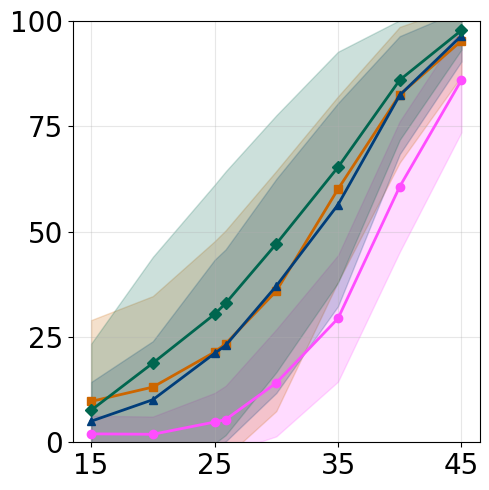

Saved: /data_fast/Work/MS_HF_cohort/images/cardiacphysiome2026//TV_Collision_regions_as_lines_LBBAP_regions.png


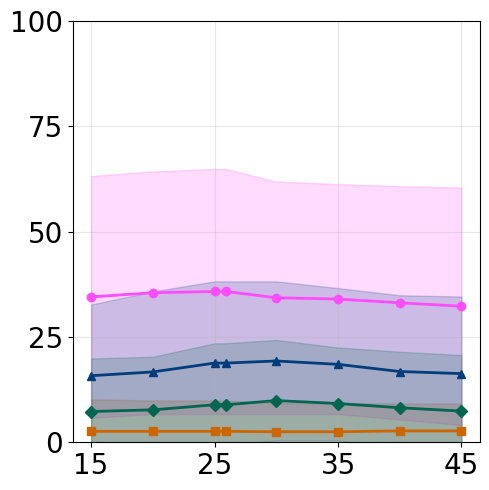

Saved: /data_fast/Work/MS_HF_cohort/images/cardiacphysiome2026//PM_Collision_regions_as_lines_LBBAP_regions.png


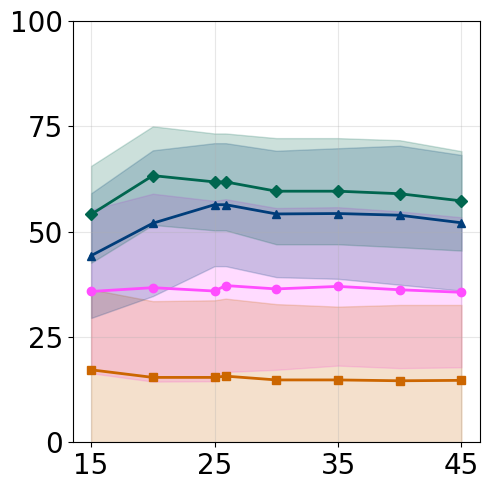

Saved: /data_fast/Work/MS_HF_cohort/images/cardiacphysiome2026//Combined_Collision_regions_as_lines_LBBAP_regions.png


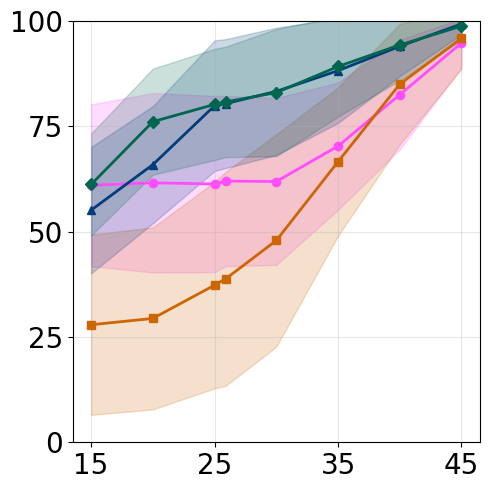

In [39]:
def get_merged_df(collision_fields=[ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision'], conestr=''): 
# Initialize empty merged DataFrame
    merged_df = None
    devices={
        "Micra": {"D": 6.7, "L": 25.9}, # AV/AV2
        "AveirAR": {"D": 6.5, "L": 32.2}, # atrial Aveir DR device 
        "AveirVR": {"D": 6.5, "L": 38} # Atrial Aveir DR device + 10mm
    }

    for device in ["Micra", "AveirAR" ,"AveirVR"]:
        D = devices[device]["D"]
        init_len = devices[device]["L"]
        
        # Calculate original volume
        vol = np.pi * ((D / 2) ** 2) * init_len

        lengths=[init_len, 15, 20, 25, 30, 35, 40, 45] # [22, 27, 32, 37, 42]:
        #lengths=[init_len]
        diameters=[]

        # If we want to keep the same volume, calculate new diameter for each new length
        for length in lengths:
            new_D = np.sqrt(vol / (np.pi * length)) * 2
            diameters.append(new_D)
            #print(f"{length:8.0f}    | {new_D:8.3f}")        
        #coll_fields=['Combined_Collision']
        merged_df=read_AHA_csv(merged_df, device, lengths, collision_fields=collision_fields, conestr=conestr) #, diameters=diameters)

    # Rename for output
    merged_df.rename(columns={"AHA_region": "AHA region"}, inplace=True)
    # Sort by AHA region
    merged_df.sort_values("AHA region", inplace=True)
    
    #display(merged_df)
    #merged_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=False)
    
    pivot_df = merged_df.set_index("AHA region").T
    pd.set_option('display.max_rows', None) # Show all rows in DataFrame display
    #display(pivot_df)
    pivot_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=True)
    return merged_df
    
def fig3_plots_with_cone(merged_df, collision_fields, fig=None, axes=None, plot_fig=False, create_new_fig=True): 
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images_cone10/plots'
    fig, axes = plot_collision_data_by_aha(merged_df, output_path=output_plot_path, plot_CS=False, collision_fields=collision_fields, fig=fig, axes=axes, plot_fig=plot_fig, create_new_fig=create_new_fig)

    return fig, axes

def fig5_plots_with_cone(merged_df, collision_fields): #CSP per device plots
    # NEW: Create plots for collision data
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images_cone10/plots'
    #plot_collision_data_by_aha(merged_df, output_path=output_plot_path)
    
    plot_collision_data_regions_as_lines(merged_df, output_path=output_plot_path, plot_CS=True, collision_fields=collision_fields)

def cardiac_physiome_plots(merged_df, collision_fields): #CSP per device plots
    # NEW: Create plots for collision data
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images/cardiacphysiome2026/'
    #plot_collision_data_by_aha(merged_df, output_path=output_plot_path)
    #for collision_field in collision_fields:
    plot_collision_data_regions_as_lines(merged_df, output_path=output_plot_path, plot_CS=True, collision_fields=collision_fields, add_init_val=False)

if __name__ == "__main__":
    # merged_df=get_merged_df()
    # fig3_plots(merged_df)
    #fig5_plots(merged_df)
    
    #collision_fields=[ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision']
    ################
    # With cone
    ################
    
    # collision_fields=['RV_Collision_Cone','TV_Collision_Cone', 'PM_Collision_Cone','Combined_Collision_Cone']
    
    # #collision_fields=['Combined_Collision_Cone'] 
    # conestr='_cone5_10'    
    # merged_df=get_merged_df(collision_fields, conestr=conestr)
    # fig3_plots_with_cone(merged_df, collision_fields)
    # #
    collision_fields=[ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision']
    #collision_fields=[ 'Combined_Collision'] #
    conestr=''
    merged_df=get_merged_df(collision_fields, conestr=conestr)
    #fig3_plots_with_cone(merged_df, collision_fields)
    #fig5_plots_with_cone(merged_df, collision_fields)
    cardiac_physiome_plots(merged_df, collision_fields)
    # for collision_field in [ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision']: 
    #     print(collision_field)
    #     #for meshsize in [1.5, 2, 5]: 
        
        
    #     conestr=f'_cone5_10'  
    #     merged_df=get_merged_df(collision_fields=[collision_field], conestr=conestr)
    #     #fig, axes=fig3_plots_with_cone(merged_df, [collision_field], fig=fig, axes=axes, plot_fig=False, create_new_fig=True) 

        
    #     merged_df_cone=get_merged_df(collision_fields=[collision_field+'_Cone'], conestr=conestr)
    #     #fig3_plots_with_cone(merged_df_cone, [collision_field+'_Cone'], fig=fig, axes=axes, plot_fig=False, create_new_fig=False)
    #     # plt.show()
    #     # conestr=''
    #     #plt.show()
    #     # #fig5_plots_with_cone(merged_df, [collision_field])
        
    #     # Usage in your code
    #     aha_regions = [2,3,8,9,14]
    #     aha_regions = [20,21,22,23]
    #     merged_df_diff, summary_df = calculate_collision_diff(merged_df, merged_df_cone,aha_regions = aha_regions)
    #     print_summary = False
    #     if print_summary:
    #         display_collision_diff_summary(summary_df)
    #     supplement_table = True
    #     if supplement_table: 
    #         format_journal_table(summary_df)


Table: Effect of ±5° Directional Rotation on Collision Risk


A. Summary by Device
--------------------------------------------------------------------------------
          Mean (%)   SD  Min  Max  N Regions
Device                                      
AveirAR       -6.1  0.7 -7.3 -5.6          5
AveirVR       -6.1  1.1 -7.8 -5.2          5
MicraTPS      -6.1  0.5 -6.9 -5.6          5

B. Summary by AHA Region
--------------------------------------------------------------------------------

Region 2:
  AveirAR     :   -7.3% ±  1.5%
  AveirVR     :   -7.8% ±  1.8%
  MicraTPS    :   -6.9% ±  1.6%

Region 3:
  AveirAR     :   -5.6% ±  3.3%
  AveirVR     :   -6.5% ±  3.8%
  MicraTPS    :   -5.6% ±  3.6%

Region 8:
  AveirAR     :   -5.6% ±  1.7%
  AveirVR     :   -5.3% ±  1.7%
  MicraTPS    :   -5.7% ±  1.7%

Region 9:
  AveirAR     :   -6.1% ±  1.9%
  AveirVR     :   -5.9% ±  2.0%
  MicraTPS    :   -6.1% ±  1.7%

Region 14:
  AveirAR     :   -5.9% ±  0.7%
  AveirVR     :   -5.2% ±  0.5%


In [204]:
# Create publication-ready summary table
summary_table = summary_df[['Device', 'AHA Region', 'Avg Difference', 'Std Difference']].copy()
summary_table.columns = ['Device', 'AHA Region', 'Mean Difference (%)', 'SD (%)']
summary_table = summary_table.sort_values(['Device', 'AHA Region'])

# Round to 1 decimal place
summary_table['Mean Difference (%)'] = summary_table['Mean Difference (%)'].round(1)
summary_table['SD (%)'] = summary_table['SD (%)'].round(1)

# Format as "value ± SD"
summary_table['Difference'] = summary_table.apply(
    lambda x: f"{x['Mean Difference (%)']:5.1f} ± {x['SD (%)']:4.1f}", axis=1
)

# Create pivot table for cleaner presentation
pivot_table = summary_table.pivot_table(
    index='Device',
    columns='AHA Region',
    values='Difference',
    aggfunc='first'
)

# Add "All Regions" column as the average across all 5 RV septal regions
all_regions_data = []
for device in pivot_table.index:
    device_data = summary_df[summary_df['Device'] == device]
    avg_mean = device_data['Avg Difference'].mean()
    avg_std = device_data['Std Difference'].mean()
    formatted_all = f"{avg_mean:5.1f} ± {avg_std:4.1f}"
    all_regions_data.append(formatted_all)

pivot_table['All Regions'] = all_regions_data

print(pivot_table.to_string())

AHA Region             2             3             8             9            14   All Regions
Device                                                                                        
AveirAR      -8.3 ±  1.9   -3.1 ±  0.7   -5.3 ±  1.4   -5.9 ±  1.6   -5.7 ±  0.6   -5.7 ±  1.2
AveirVR      -8.6 ±  2.2   -2.9 ±  1.0   -5.0 ±  1.4   -5.1 ±  1.7   -5.1 ±  0.4   -5.3 ±  1.3
MicraTPS     -8.0 ±  1.7   -3.5 ±  0.7   -5.5 ±  1.5   -6.5 ±  1.8   -6.1 ±  0.7   -5.9 ±  1.3


In [55]:
import pandas as pd
import numpy as np

mainpath='/data_fast/Work/MS_HF_cohort/images/'

for device in ['AveirVR', 'AveirAR', 'Micra']: # #
    if device == 'AveirVR':
        init_len= 38
    elif device == 'AveirAR': 
        init_len= 32.2
    elif device == 'Micra': 
        init_len = 25.9
    else: 
        print(f'WARNING - DEVICE: {device} is not AveirVR, AveirAR or Micra')

    lengths=[init_len] #, 15, 20, 25, 30, 35, 40, 45] # [22, 27, 32, 37, 42]:
    for length in lengths:
        all_collision_values = []
        for AHA_region in [2,3,8,9,14]: 
            csv_file=f'{mainpath}/{device}/csv/{AHA_region}_L{length}.csv'
            print(f'CSV file: {csv_file}')  
            df = pd.read_csv(csv_file)            
            print(f'AHA region {AHA_region}: MEAN: {np.mean(df['collision_value']*10):1.1f}%, STD: {10*np.std(df['collision_value']):1.1f}%')
            all_collision_values.extend(df['collision_value'].tolist())

        print(f'All collision values for {device} at length {length}: {np.mean(all_collision_values)*10:1.1f}%, STD: {10*np.std(all_collision_values):1.1f}%')  




CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/2_L38.csv
AHA region 2: MEAN: 79.9%, STD: 15.9%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/3_L38.csv
AHA region 3: MEAN: 94.4%, STD: 8.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/8_L38.csv
AHA region 8: MEAN: 88.5%, STD: 14.8%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/9_L38.csv
AHA region 9: MEAN: 91.6%, STD: 10.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/14_L38.csv
AHA region 14: MEAN: 75.2%, STD: 24.1%
All collision values for AveirVR at length 38: 85.0%, STD: 18.2%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/2_L32.2.csv
AHA region 2: MEAN: 54.6%, STD: 19.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/3_L32.2.csv
AHA region 3: MEAN: 93.6%, STD: 9.3%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/8_L32.2.csv
AHA region 8: MEAN: 78.3%, STD: 21.1%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/9_L32.2.csv
AH

In [2]:
merged_df

NameError: name 'merged_df' is not defined

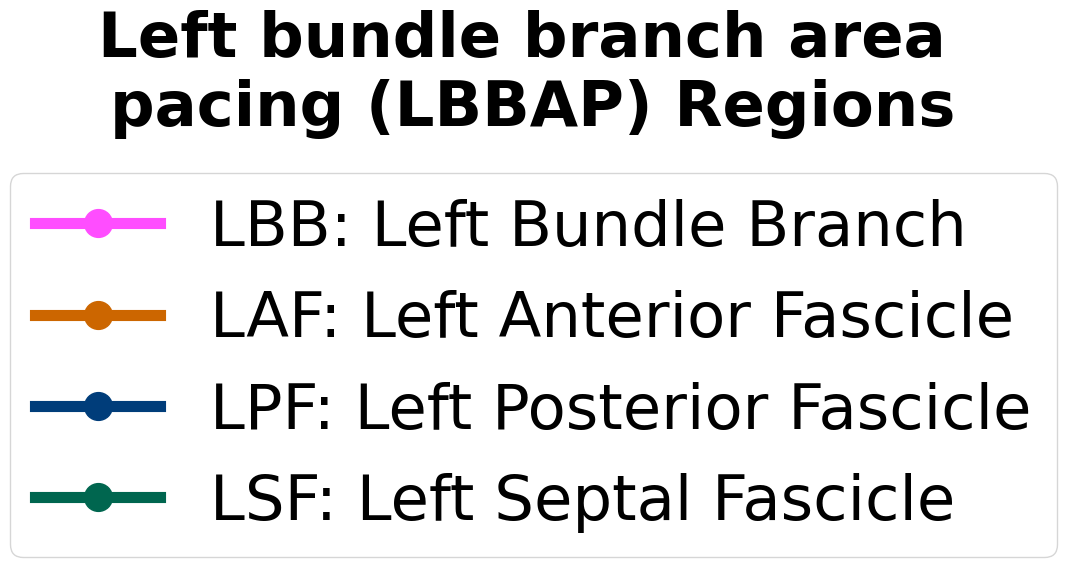

In [138]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def make_legend_box(fontsize=45): 
    if fontsize==45: 
        y_offset=-0.8
    elif fontsize==30: 
        y_offset=-0.2
    else: 
        y_offset=-0.1

    # Combined dictionary: {id: (name, color)}
    regions = {
        20: ('LBB: Left Bundle Branch', "#FF4DFF"),
        21: ('LAF: Left Anterior Fascicle', '#cc6600'),
        22: ('LPF: Left Posterior Fascicle', "#003d7a"),
        23: ('LSF: Left Septal Fascicle', "#00664f")
    }

    # Create legend handles (solid line + circle marker)
    legend_elements = [
        Line2D([0], [0], color=color, lw=8, marker='o', markersize=20, linestyle='-', label=name)
        for name, color in regions.values()
    ]

    # Create a figure for the legend only
    fig = plt.figure(figsize=(4, 2))

    # Add the legend to the figure
    # Add a bold figure title
    fig.suptitle(
        "Left bundle branch area \npacing (LBBAP) Regions",
        fontsize=fontsize,
        fontweight='bold',
        color='black'
    )
    fig.legend(
        handles=legend_elements,
        loc='center',
        bbox_to_anchor=(0.5, y_offset),    # move legend down (0.45 = 45% up from bottom) 
        ncol=1,
        frameon=True,
        fontsize=fontsize)

    # Hide axes
    plt.axis('off')
    plt.subplots_adjust(top=0.85)
    # Save or show
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images/plots'
    plt.savefig(f'{output_plot_path}/legend_only.png', bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    # For figure 5 plots legend
    #make_legend_box(45)

    # For Figure 1, small plot 
    make_legend_box(45)


Saved: /data_fast/Work/MS_HF_cohort/images/plots/device_legend_only.png


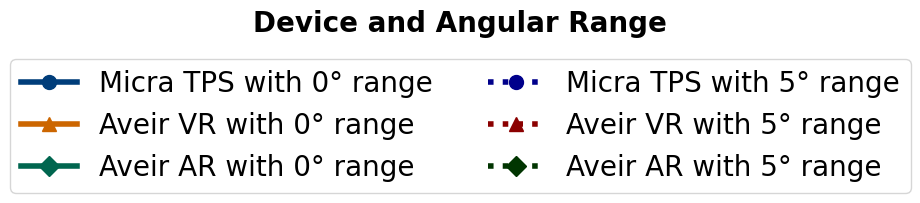

In [178]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def make_device_legend_box(fontsize=45, output_plot_path='/data_fast/Work/MS_HF_cohort/images/plots',col=1): 
    if fontsize == 45: 
        y_offset = 0.0
    elif fontsize == 30: 
        y_offset = 0.3
    else: 
        y_offset = 0.5
    if col==2:
        y_offset=0.4
        lw=4
        markersize=10
        # Create a figure for the legend only
        fig = plt.figure(figsize=(6, 2))
    else:
        lw=8
        markersize=20
        # Create a figure for the legend only
        fig = plt.figure(figsize=(6, 4))
    # Light colors for fixed data
    light_colors = {
        'Micra': '#003d7a',
        'MicraTPS': '#003d7a',
        'AveirVR': '#cc6600',
        'AveirAR': '#00664f'
    }
    
    # Dark colors for cone data (with 10 degree)
    dark_colors = {
        'AveirVR': '#8B0000',    # dark red
        'AveirAR': "#013501",     # dark green
        'MicraTPS': '#00008B',   # dark blue
        'Micra': '#002B00'       # very dark green
    }
    device_markers = {'MicraTPS': 'o', 'AveirVR': '^', 'AveirAR': 'D'} 
    # Device names for display
    device_names = {
        'MicraTPS': 'Micra TPS',
        'AveirVR': 'Aveir VR',
        'AveirAR': 'Aveir AR'
    }
    
    # Create legend handles
    legend_elements = []
    
    # Add fixed devices (light colors)
    for device in ['MicraTPS', 'AveirVR', 'AveirAR']:
        legend_elements.append(
            Line2D([0], [0], color=light_colors[device], lw=lw, marker=device_markers[device], 
                   markersize=markersize, linestyle='-', 
                   label=f"{device_names[device]} with 0° range")
        )
    
    # Add cone devices (dark colors)
    for device in ['MicraTPS', 'AveirVR', 'AveirAR']:
        legend_elements.append(
            Line2D([0], [0], color=dark_colors[device], lw=lw, marker=device_markers[device], 
                   markersize=markersize, linestyle=':', 
                   label=f"{device_names[device]} with 5° range")
        )
    
    
    
    # Add a bold figure title
    fig.suptitle(
        "Device and Angular Range",
        fontsize=fontsize,
        fontweight='bold',
        color='black'
    )
    
    # Add the legend to the figure
    fig.legend(
        handles=legend_elements,
        loc='center',
        bbox_to_anchor=(0.5, y_offset),    # move legend down 
        ncol=col,
        frameon=True,
        fontsize=fontsize
    )
    
    # Hide axes
    plt.axis('off')
    plt.subplots_adjust(top=0.85)
    
    # Save or show
    plt.savefig(f'{output_plot_path}/device_legend_only.png', bbox_inches='tight', dpi=300)
    print(f'Saved: {output_plot_path}/device_legend_only.png')
    plt.show()

if __name__ == "__main__":
    # For figure legend
    make_device_legend_box(20,col=2)